# AutoBNN Experimental Barrier Plots for D3 Sweep

This notebook visualizes the merged AutoBNN experimental runs in
`/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep`.

It now includes both:
- the earlier weaker-constraint runs: `0, 1e-6, 1e-4, 1e-2`
- the newer stronger-constraint runs: `1e-1, 1, 1e2, 1e3`

Figures are written to scratch so the notebook can be run on a headless machine.

In [1]:
import os
import sys
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import scienceplots
    plt.style.use(['science', 'no-latex', 'ieee'])
except ModuleNotFoundError:
    pass

plt.rc('axes', labelsize=14)
plt.rcParams['axes.titlesize'] = 20
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=10)
plt.rc('lines', linewidth=2)



REPO_ROOT = Path('/mnt/home/philipaa/research/barrier-extraction')
SRC = REPO_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.append(str(SRC))

from utils import paper_three_point_barrier
from train import percentile_bands

path_base = Path('/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep')
save_dir = path_base / 'plots'
save_dir.mkdir(parents=True, exist_ok=True)

DE_STENCIL = 2

titles = (
    '16O208PbMorton1999',
    '40Ca40CaMontagnoli2012',
    '48Ca40CaJiang2010',
    '48Ca48CaStefanini2009',
)

reaction_labels = [
    r'$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$',
    r'$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$',
    r'$^{48}\mathrm{Ca} + ^{40}\mathrm{Ca}$',
    r'$^{48}\mathrm{Ca} + ^{48}\mathrm{Ca}$',
]

ylims = {
    '16O208PbMorton1999': (-100, 1000),
    '40Ca40CaMontagnoli2012': (-100, 2000),
    '48Ca40CaJiang2010': (-100, 1000),
    '48Ca48CaStefanini2009': (-100, 1500),
}

selected_sub_indices = {
    '16O208PbMorton1999': 5,
    '40Ca40CaMontagnoli2012': 6,
    '48Ca40CaJiang2010': 2,
    '48Ca48CaStefanini2009': 8,
}

weak_lambda_specs = [
    ('0', '0.0'),
    ('1e-6', '1e-6'),
    ('1e-4', '1e-4'),
    ('1e-2', '1e-2'),
]

strong_lambda_specs = [
    ('1e-1', '1e-1'),
    ('1', '1.0'),
    ('1e2', '1e2'),
    ('1e3', '1e3'),
]

all_lambda_specs = weak_lambda_specs + strong_lambda_specs

lambda_colors = {
    '0.0': 'black',
    '1e-6': '#1f77b4',
    '1e-4': '#2ca02c',
    '1e-2': '#d62728',
    '1e-1': '#9467bd',
    '1.0': '#8c564b',
    '1e2': '#e377c2',
    '1e3': '#7f7f7f',
}

lambda_linestyles = {
    '0.0': '--',
    '1e-6': '--',
    '1e-4': '--',
    '1e-2': '--',
    '1e-1': '--',
    '1.0': '--',
    '1e2': '--',
    '1e3': '--',
}

lambda_display_labels = {
    '0.0': r'$0$',
    '1e-6': r'$10^{-6}$',
    '1e-4': r'$10^{-4}$',
    '1e-2': r'$10^{-2}$',
    '1e-1': r'$10^{-1}$',
    '1.0': r'$1$',
    '1e2': r'$10^{2}$',
    '1e3': r'$10^{3}$',
}

lambda_line_alpha = 0.72
lambda_line_width = 1.8

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
})

/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


In [2]:
def merged_h5_path(title, lambda_tag):
    return path_base / f'experiments_{title}_bnn_soc_d3lam_{lambda_tag}.h5_8x1000_lognormal_soc_d3lam_{lambda_tag}'


def available_group_names(h5_path):
    with h5py.File(h5_path, 'r') as f:
        return sorted(f.keys())


def choose_group_name(h5_path, dataset_idx, preferred_sub_index):
    preferred = f'{int(dataset_idx):05d}_run{int(preferred_sub_index):02d}'
    groups = available_group_names(h5_path)
    if preferred in groups:
        return preferred, False, len(groups)
    if not groups:
        raise ValueError(f'No groups found in {h5_path}')
    return groups[0], True, len(groups)


def load_panel_payload(dataset_idx, title, lambda_tag, preferred_sub_index):
    h5_path = merged_h5_path(title, lambda_tag)
    group_name, used_fallback, num_groups = choose_group_name(h5_path, dataset_idx, preferred_sub_index)

    with h5py.File(h5_path, 'r') as f:
        grp = f[group_name]
        x = grp['x_pred'][:]
        y_samples = grp['y_samples'][:]
        D_samples = grp['d2_samples'][:]
        E_data = grp['E_data'][:]
        Sigma_data = grp['Sigma_data'][:]
        Sigma_err = grp['Sigma_err'][:]

    D_mean = D_samples.mean(axis=0)
    bands = percentile_bands(D_samples, levels=(0.68,))
    D_lo = bands['lower_68']
    D_hi = bands['upper_68']

    E_pts, D_pts, D_pts_err = paper_three_point_barrier(
        E_data, Sigma_data, Sigma_err, dE=DE_STENCIL
    )

    return {
        'h5_path': str(h5_path),
        'group_name': group_name,
        'used_fallback': used_fallback,
        'num_groups': num_groups,
        'x': x,
        'y_samples': y_samples,
        'D_samples': D_samples,
        'D_mean': D_mean,
        'D_lo': D_lo,
        'D_hi': D_hi,
        'E_data': E_data,
        'Sigma_data': Sigma_data,
        'Sigma_err': Sigma_err,
        'E_pts': E_pts,
        'D_pts': D_pts,
        'D_pts_err': D_pts_err,
    }


def plot_barrier_panel(ax, payload, title_text, ylim, color='red', show_legend=False):
    x = payload['x']
    E_data = payload['E_data']
    E_pts = payload['E_pts']
    D_mean = payload['D_mean']
    D_lo = payload['D_lo']
    D_hi = payload['D_hi']
    D_pts = payload['D_pts']
    D_pts_err = payload['D_pts_err']

    line, = ax.plot(x, D_mean, '--', color=color, linewidth=1.8, label='AutoBNN mean')
    band = ax.fill_between(x, D_lo, D_hi, color=color, alpha=0.18, label='AutoBNN 68% CI')
    pts = ax.errorbar(
        E_pts,
        D_pts,
        yerr=D_pts_err,
        fmt='o',
        color='black',
        ms=4,
        lw=1,
        capsize=2,
        label='Paper 3-point formula',
    )

    ax.set_xlim(E_data.min(), E_data.max())
    ax.set_ylim(ylim)
    ax.set_title(title_text)
    if show_legend:
        ax.legend([line, band, pts], ['AutoBNN mean', 'AutoBNN 68% CI', 'Paper 3-point formula'], loc='upper right', frameon=True)


def build_grid(lambda_specs, figure_stem):
    records = []
    fig, axes = plt.subplots(len(lambda_specs), 4, figsize=(16, 3.5 * len(lambda_specs)), sharex=False, layout='constrained')

    if len(lambda_specs) == 1:
        axes = np.asarray([axes])

    for row_idx, (lambda_tag, lambda_label) in enumerate(lambda_specs):
        for col_idx, (title, rxn_label) in enumerate(zip(titles, reaction_labels)):
            ax = axes[row_idx, col_idx]
            payload = load_panel_payload(col_idx, title, lambda_tag, selected_sub_indices[title])
            panel_title = f'{rxn_label}\n$\\lambda_{{d3}}={lambda_label}$'
            plot_barrier_panel(
                ax=ax,
                payload=payload,
                title_text=panel_title,
                ylim=ylims[title],
                color=lambda_colors[lambda_label],
                show_legend=(row_idx == 0 and col_idx == 0),
            )

            if row_idx == len(lambda_specs) - 1:
                ax.set_xlabel(r'$E_{\mathrm{c.m.}}$ (MeV)')
            if col_idx == 0:
                ax.set_ylabel(r'$D_f(E)$ (mb/MeV)')

            ax.text(
                0.03, 0.95, f'({chr(97 + row_idx * len(titles) + col_idx)})',
                transform=ax.transAxes,
                ha='left',
                va='top',
                fontsize=12,
            )

            records.append({
                'dataset_idx': col_idx,
                'dataset': title,
                'reaction_label': rxn_label,
                'd3_lambda_tag': lambda_tag,
                'd3_lambda_label': lambda_label,
                'preferred_run': selected_sub_indices[title],
                'chosen_group_name': payload['group_name'],
                'used_fallback_group': payload['used_fallback'],
                'num_available_groups': payload['num_groups'],
                'num_barrier_samples': int(payload['D_samples'].shape[0]),
                'h5_path': payload['h5_path'],
            })

    out_png = save_dir / f'{figure_stem}.png'
    out_pdf = save_dir / f'{figure_stem}.pdf'
    fig.savefig(out_png, bbox_inches='tight')
    fig.savefig(out_pdf, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    return pd.DataFrame(records), out_png, out_pdf

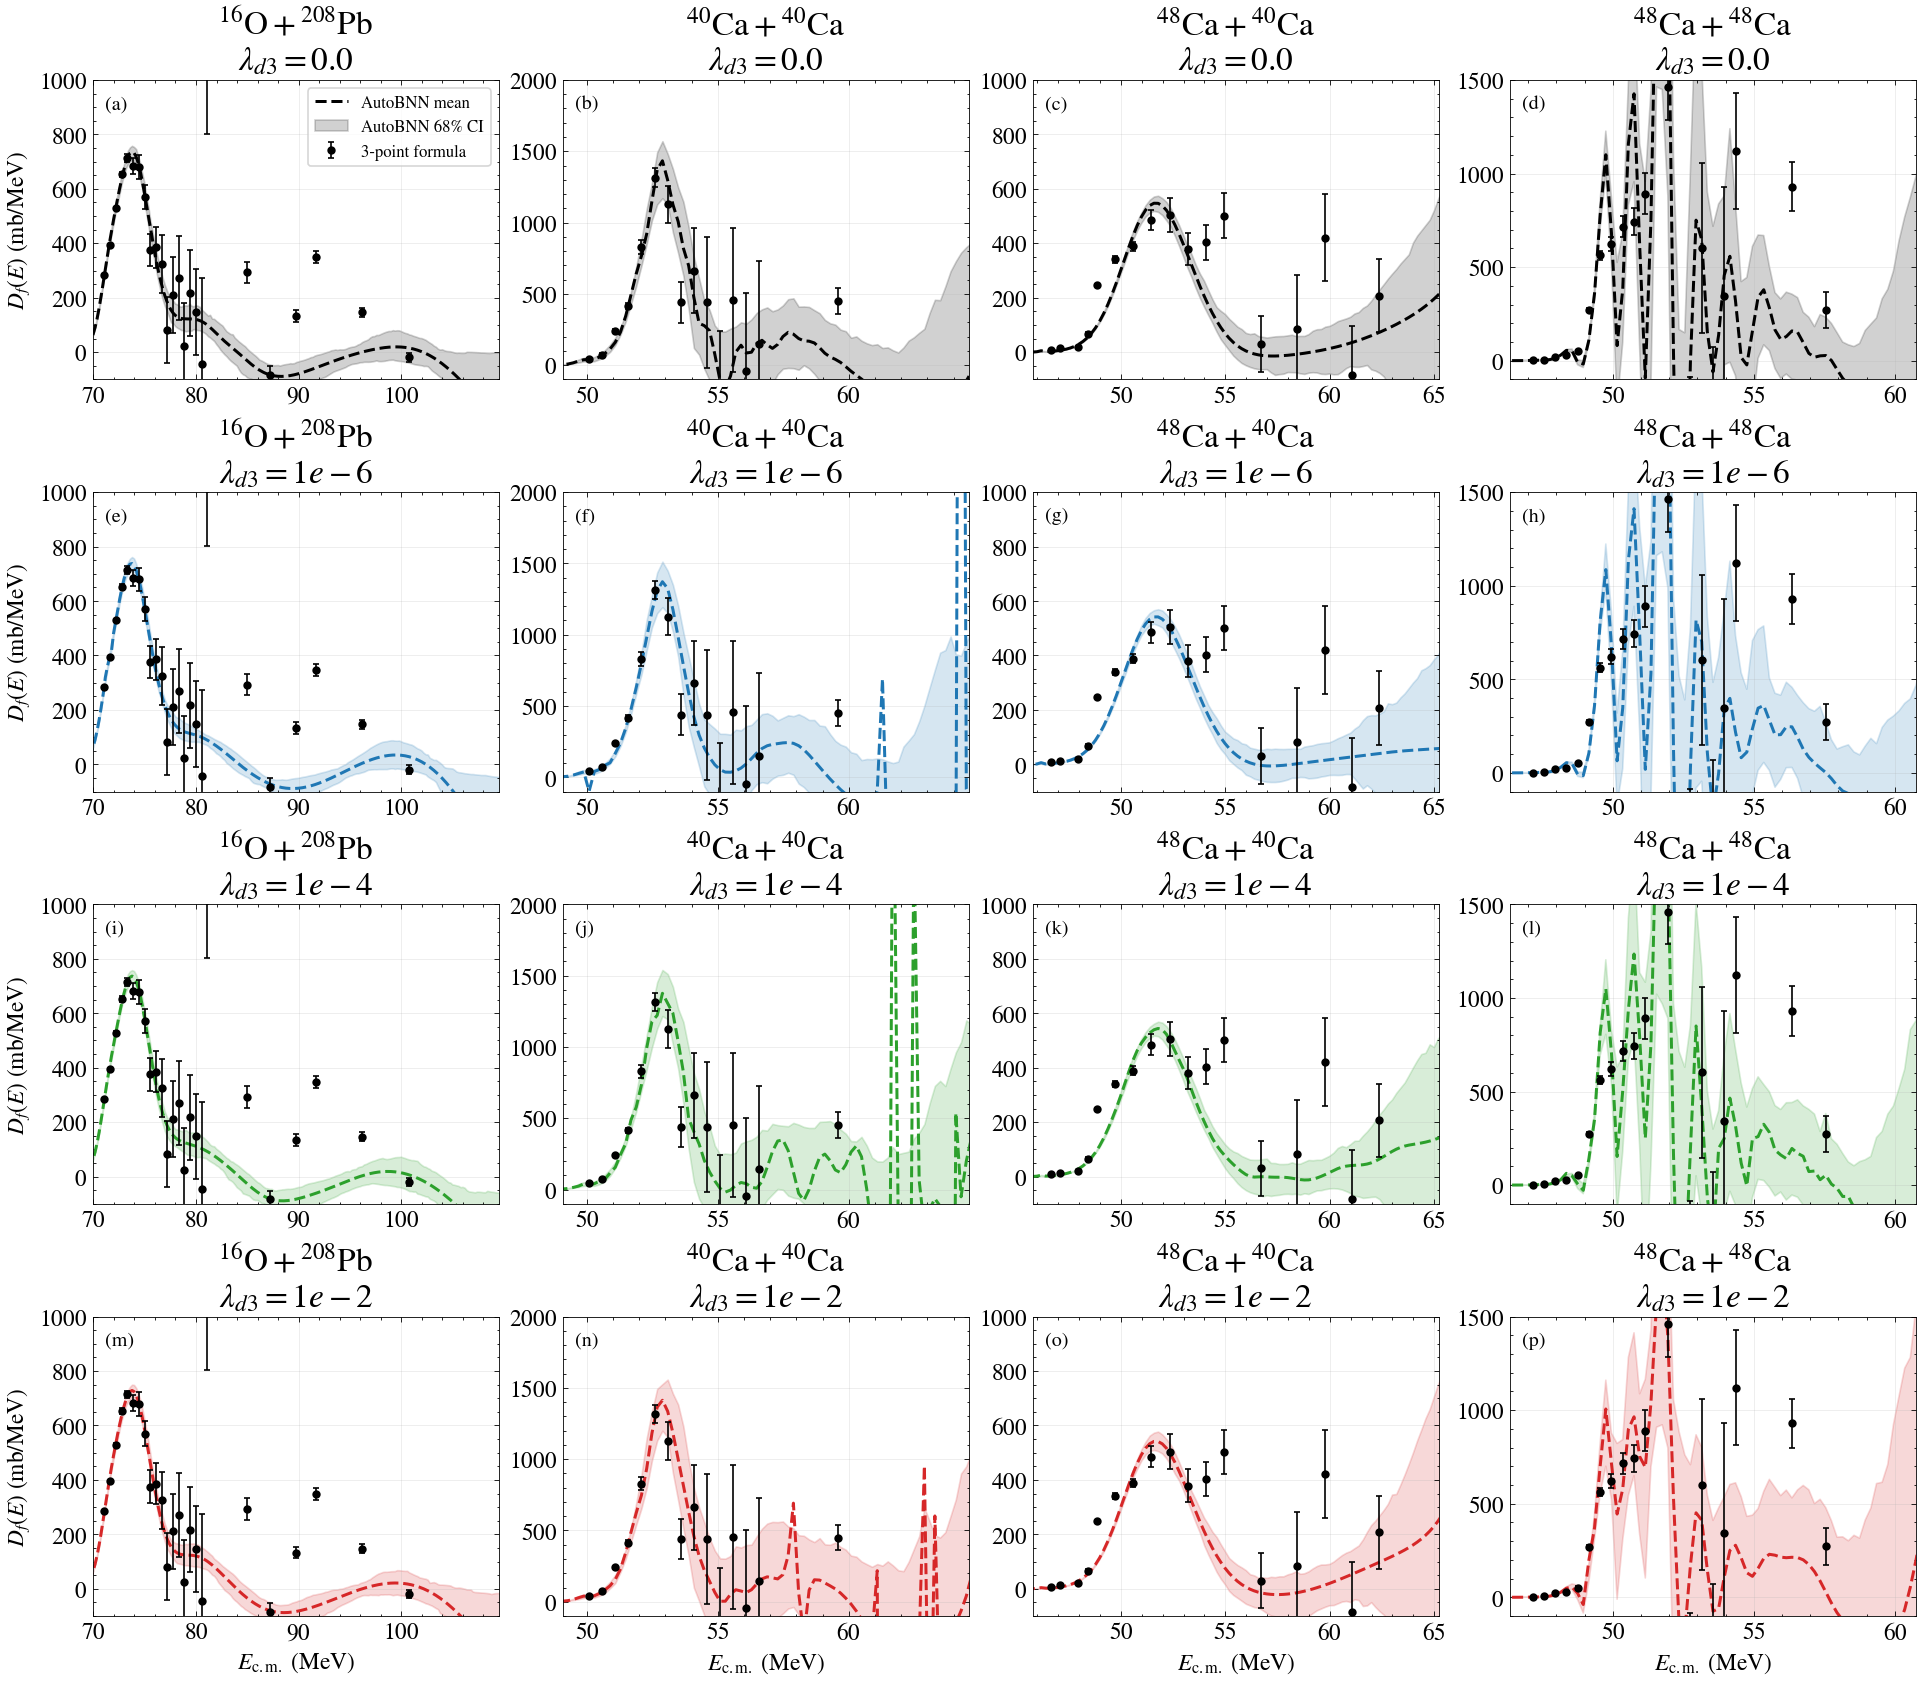

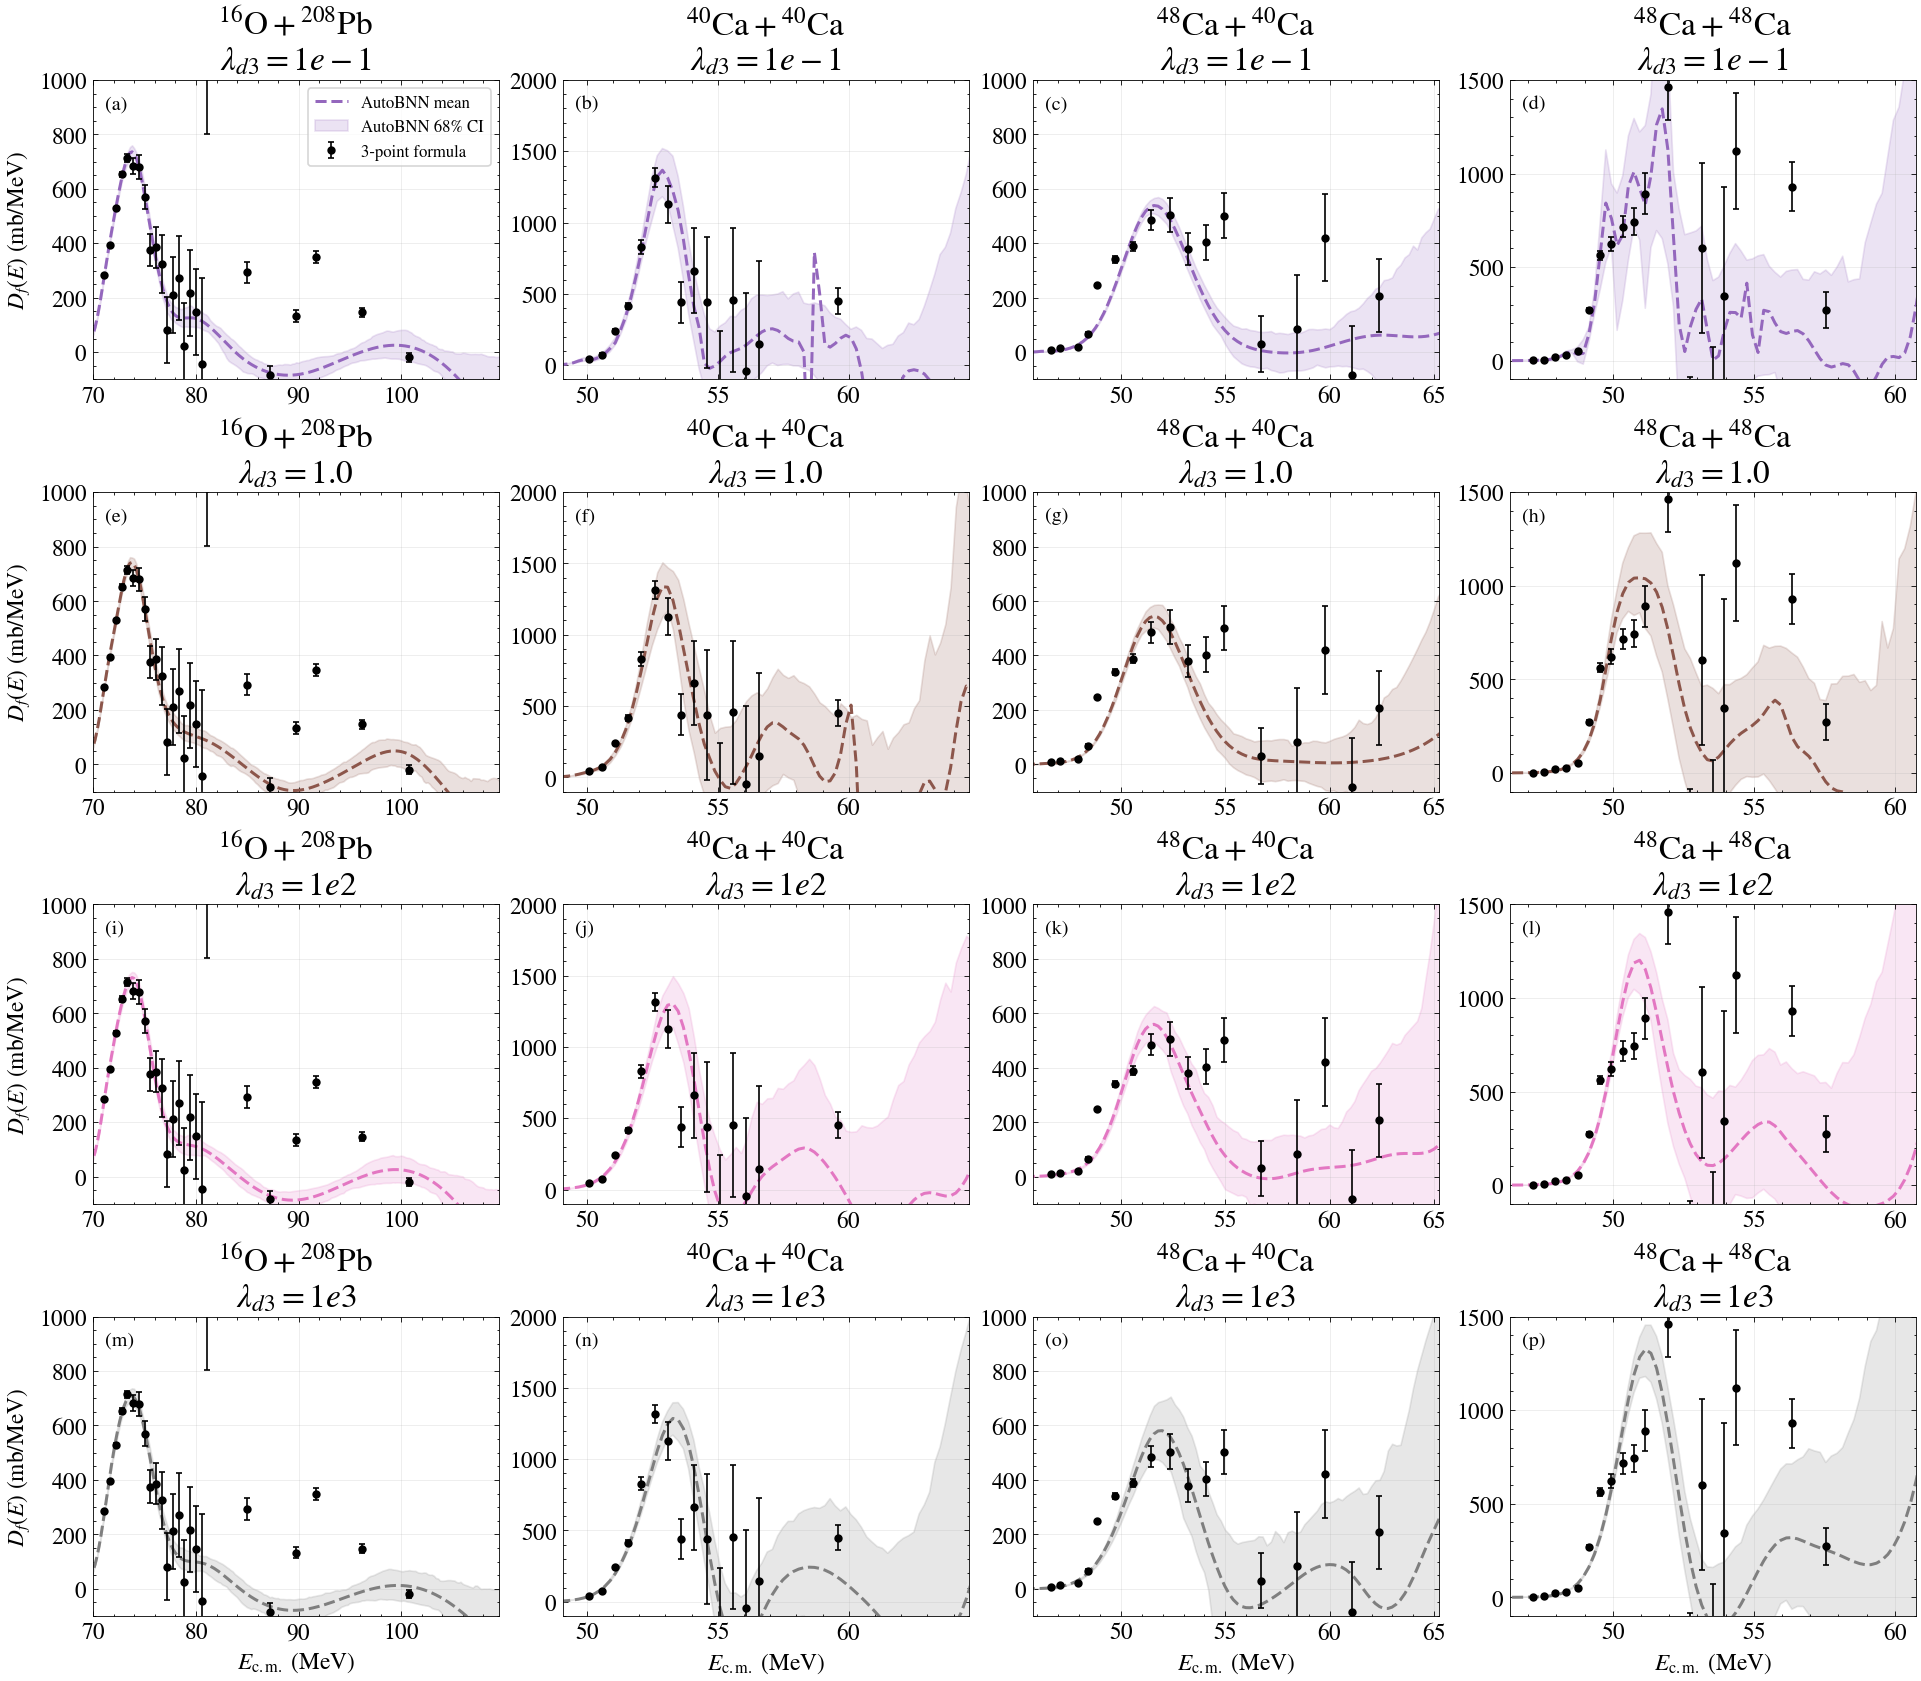

,dataset_idx,dataset,reaction_label,d3_lambda_tag,d3_lambda_label,preferred_run,chosen_group_name,used_fallback_group,num_available_groups,num_barrier_samples,h5_path
0,0,16O208PbMorton1999,$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$,0,0.0,5,00000_run05,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
1,1,40Ca40CaMontagnoli2012,$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$,0,0.0,6,00001_run06,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
2,2,48Ca40CaJiang2010,$^{48}\mathrm{Ca} + ^{40}\mathrm{Ca}$,0,0.0,2,00002_run02,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
3,3,48Ca48CaStefanini2009,$^{48}\mathrm{Ca} + ^{48}\mathrm{Ca}$,0,0.0,8,00003_run08,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
4,0,16O208PbMorton1999,$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$,1e-6,1e-6,5,00000_run05,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
5,1,40Ca40CaMontagnoli2012,$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$,1e-6,1e-6,6,00001_run06,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
6,2,48Ca40CaJiang2010,$^{48}\mathrm{Ca} + ^{40}\mathrm{Ca}$,1e-6,1e-6,2,00002_run02,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
7,3,48Ca48CaStefanini2009,$^{48}\mathrm{Ca} + ^{48}\mathrm{Ca}$,1e-6,1e-6,8,00003_run08,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
8,0,16O208PbMorton1999,$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$,1e-4,1e-4,5,00000_run06,True,2,100,/mnt/home/philipaa/scratch/barrier-paper-resul...
9,1,40Ca40CaMontagnoli2012,$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$,1e-4,1e-4,6,00001_run06,False,10,100,/mnt/home/philipaa/scratch/barrier-paper-resul...


In [3]:
weak_summary_df, weak_png, weak_pdf = build_grid(
    lambda_specs=weak_lambda_specs,
    figure_stem='experimental_d3_sweep_weak_barriers_grid',
)

strong_summary_df, strong_png, strong_pdf = build_grid(
    lambda_specs=strong_lambda_specs,
    figure_stem='experimental_d3_sweep_strong_barriers_grid',
)

summary_df = pd.concat([weak_summary_df, strong_summary_df], ignore_index=True)
summary_df

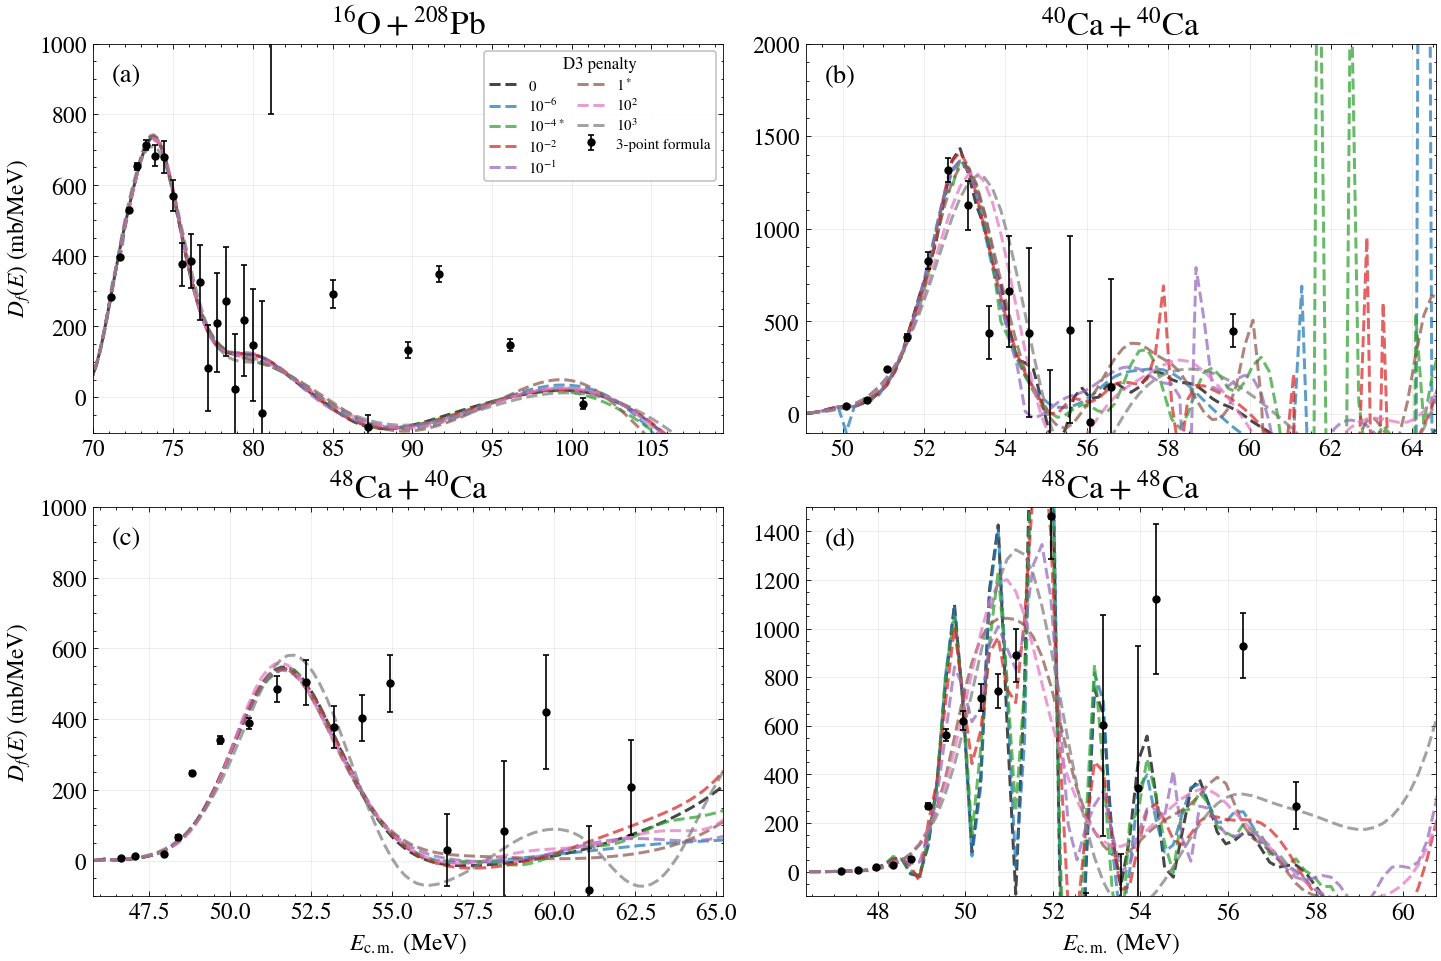

/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_all_lambda_overlay.png
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_all_lambda_overlay.pdf


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False, layout='constrained')
axes = axes.ravel()

for idx, (title, rxn_label, ax) in enumerate(zip(titles, reaction_labels, axes)):
    data_ref = None
    for lambda_tag, lambda_label in all_lambda_specs:
        payload = load_panel_payload(idx, title, lambda_tag, selected_sub_indices[title])
        data_ref = payload
        label = lambda_display_labels[lambda_label]
        if payload['used_fallback']:
            label += r'$^*$'
        ax.plot(
            payload['x'],
            payload['D_mean'],
            color=lambda_colors[lambda_label],
            linestyle=lambda_linestyles[lambda_label],
            linewidth=lambda_line_width,
            alpha=lambda_line_alpha,
            label=label,
        )

    ax.errorbar(
        data_ref['E_pts'],
        data_ref['D_pts'],
        yerr=data_ref['D_pts_err'],
        fmt='o',
        color='black',
        ms=4,
        lw=1,
        capsize=2,
        label='Paper 3-point formula',
    )

    ax.set_xlim(data_ref['E_data'].min(), data_ref['E_data'].max())
    ax.set_ylim(ylims[title])
    ax.set_title(rxn_label)

    if idx in [2, 3]:
        ax.set_xlabel(r'$E_{\mathrm{c.m.}}$ (MeV)')
    if idx in [0, 2]:
        ax.set_ylabel(r'$D_f(E)$ (mb/MeV)')

    ax.text(
        0.03, 0.95, f'({chr(97 + idx)})',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=16,
    )

axes[0].legend(
    loc='upper right',
    frameon=True,
    framealpha=0.9,
    facecolor='white',
    edgecolor='0.75',
    fontsize=9,
    title='D3 penalty',
    title_fontsize=10,
    ncol=2,
    borderpad=0.35,
    labelspacing=0.25,
    columnspacing=0.8,
    handlelength=1.8,
)

overlay_png = save_dir / 'experimental_d3_sweep_all_lambda_overlay.png'
overlay_pdf = save_dir / 'experimental_d3_sweep_all_lambda_overlay.pdf'
fig.savefig(overlay_png, bbox_inches='tight')
fig.savefig(overlay_pdf, bbox_inches='tight')
plt.show()
plt.close(fig)

print(overlay_png)
print(overlay_pdf)

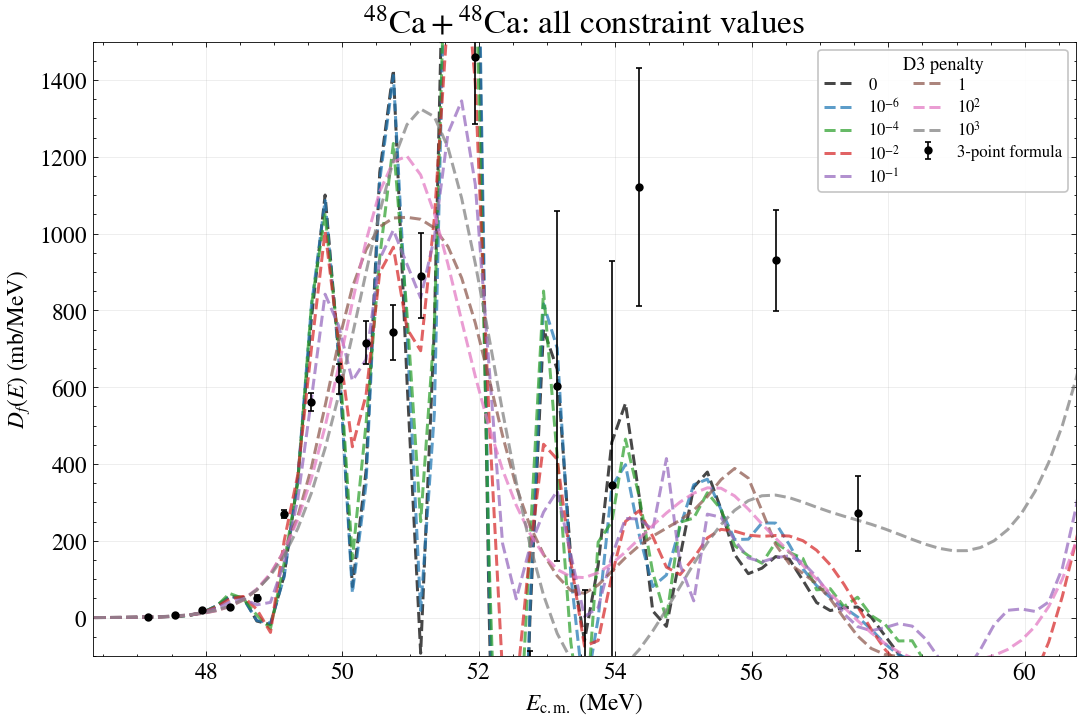

Saved:
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_weak_barriers_grid.png
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_weak_barriers_grid.pdf
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_strong_barriers_grid.png
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_strong_barriers_grid.pdf
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_all_lambda_overlay.png
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_all_lambda_overlay.pdf
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_stefanini_all_lambda_overlay.png
/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep/plots/experimental_d3_sweep_stefanini_all_lambda_overl

In [5]:
stef_idx = titles.index('48Ca48CaStefanini2009')
stef_title = titles[stef_idx]
stef_label = reaction_labels[stef_idx]

fig, ax = plt.subplots(1, 1, figsize=(9, 6), layout='constrained')

data_ref = None
for lambda_tag, lambda_label in all_lambda_specs:
    payload = load_panel_payload(stef_idx, stef_title, lambda_tag, selected_sub_indices[stef_title])
    data_ref = payload
    label = lambda_display_labels[lambda_label]
    ax.plot(
        payload['x'],
        payload['D_mean'],
        color=lambda_colors[lambda_label],
        linestyle=lambda_linestyles[lambda_label],
        linewidth=lambda_line_width,
        alpha=lambda_line_alpha,
        label=label,
    )

ax.errorbar(
    data_ref['E_pts'],
    data_ref['D_pts'],
    yerr=data_ref['D_pts_err'],
    fmt='o',
    color='black',
    ms=4,
    lw=1,
    capsize=2,
    label='Paper 3-point formula',
)

ax.set_xlim(data_ref['E_data'].min(), data_ref['E_data'].max())
ax.set_ylim(ylims[stef_title])
ax.set_xlabel(r'$E_{\mathrm{c.m.}}$ (MeV)')
ax.set_ylabel(r'$D_f(E)$ (mb/MeV)')
ax.set_title(f'{stef_label}: all constraint values')
ax.legend(
    loc='upper right',
    frameon=True,
    framealpha=0.9,
    facecolor='white',
    edgecolor='0.75',
    fontsize=10,
    title='D3 penalty',
    title_fontsize=11,
    ncol=2,
    borderpad=0.35,
    labelspacing=0.25,
    columnspacing=0.8,
    handlelength=1.8,
)

stef_png = save_dir / 'experimental_d3_sweep_stefanini_all_lambda_overlay.png'
stef_pdf = save_dir / 'experimental_d3_sweep_stefanini_all_lambda_overlay.pdf'
fig.savefig(stef_png, bbox_inches='tight')
fig.savefig(stef_pdf, bbox_inches='tight')
plt.show()
plt.close(fig)

summary_csv = save_dir / 'experimental_d3_sweep_selected_groups_all_lambda.csv'
summary_df.to_csv(summary_csv, index=False)

print('Saved:')
print(weak_png)
print(weak_pdf)
print(strong_png)
print(strong_pdf)
print(overlay_png)
print(overlay_pdf)
print(stef_png)
print(stef_pdf)
print(summary_csv)